<a href="https://colab.research.google.com/github/laksamanaap/PCVK_Ganjil_2026/blob/main/P9/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9

In [13]:
from google.colab import drive
drive.mount('/content/drive')

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters, io, color, img_as_float
from skimage.morphology import skeletonize, thin

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
import os

# Point to the directory containing the images, not the file itself
image_dir = '/content/drive/MyDrive/PCVK_img'

print(os.listdir(image_dir))

['lena_lc.jpg', 'lena.jpg', 'KTM1A.jpg', 'KTM1B.jpeg', 'KTM1C.jpg', 'KTM1D.jpg', 'mandrill.tiff', 'djawatan.jpg', 'gradient.jpg', 'sudoku-original.jpg', 'lena_gs_lc2.jpg', 'noisy2.png', 'lily (1).jpg', 'lily.jpg', 'ktp_fulan.jpg', 'ktp_fulani.jpg', 'ktp_dama_dummy.jpg', 'ktp_laksa_dummy.jpg', 'plat_nomer.png']


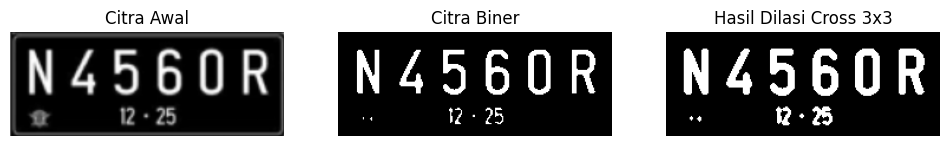

In [16]:
# Dilasi tanpa library
def dilasi_citra(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Structuring Element Cross 3x3
    SED = np.array([
        [0, 1, 0],
        [1, 1, 1],
        [0, 1, 0]
    ], dtype=np.uint8)

    constant = (w - 1) // 2

    for i in range(constant, p - constant):
        for j in range(constant, q - constant):
            temp = F[
                i-constant:i+constant+1,
                j-constant:j+constant+1
            ]

            imgD[i, j] = np.max(temp * SED) if w == 3 else np.max(temp)

    return imgD


img = cv2.imread(f'{image_dir}/plat_nomer.png', cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Gambar plat nomer.jpg tidak ditemukan.")

_, thresh = cv2.threshold(img, 125, 255, cv2.THRESH_BINARY)

hasil_dilasi = dilasi_citra(thresh, 3)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(hasil_dilasi, cmap='gray')
plt.title('Hasil Dilasi Cross 3x3')
plt.axis('off')

plt.show()

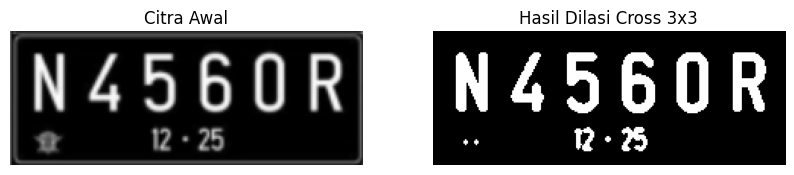

In [17]:
img = cv2.imread(f'{image_dir}/plat_nomer.png')

if img is None:
    raise FileNotFoundError("Gambar plat nomer.png tidak ditemukan.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
_, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
dilasi = cv2.dilate(thresh, kernel, iterations=1)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(dilasi, cv2.COLOR_BGR2RGB))
plt.title('Hasil Dilasi Cross 3x3')
plt.axis('off')

plt.show()

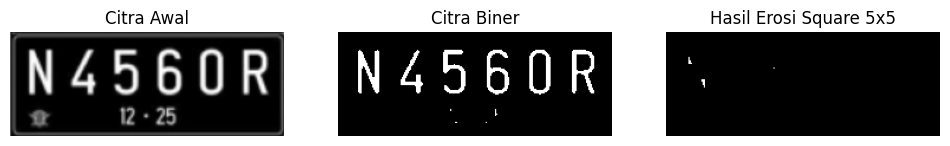

In [18]:
def erosi_citra(F, k):
    m, n = F.shape
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[
                i-constant:i+constant+1,
                j-constant:j+constant+1
            ]

            imgE[i, j] = np.min(temp * SE)

    return imgE


img = cv2.imread(f'{image_dir}/plat_nomer.png', cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Gambar plat nomer.jpg tidak ditemukan.")

_, thresh = cv2.threshold(img, 175, 255, cv2.THRESH_BINARY)

hasil_erosi = erosi_citra(thresh, 5)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(hasil_erosi, cmap='gray')
plt.title('Hasil Erosi Square 5x5')
plt.axis('off')

plt.show()

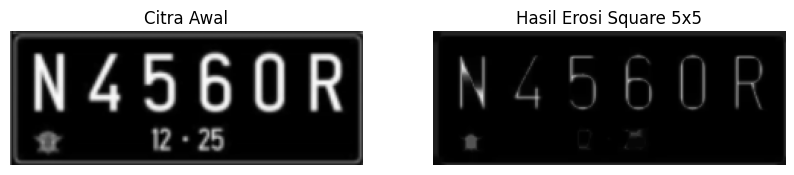

In [19]:
img = cv2.imread(f'{image_dir}/plat_nomer.png')

if img is None:
    raise FileNotFoundError("Gambar plat nomer.jpg tidak ditemukan.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
erosi = cv2.erode(img, kernel, iterations=1)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(erosi, cv2.COLOR_BGR2RGB))
plt.title('Hasil Erosi Square 5x5')
plt.axis('off')

plt.show()

In [20]:
def morfologi_manual(F, SE, operasi):
    F = np.where(F > 0, 255, 0).astype(np.uint8)

    tinggi, lebar = F.shape
    kh, kw = SE.shape
    ph, pw = kh // 2, kw // 2

    # Padding untuk menangani piksel di tepi citra
    nilai_padding = 255 if operasi == 'erosi' else 0
    padded = cv2.copyMakeBorder(
        F, ph, ph, pw, pw,
        cv2.BORDER_CONSTANT,
        value=nilai_padding
    )

    hasil = np.zeros_like(F)

    for i in range(tinggi):
        for j in range(lebar):
            area = padded[i:i+kh, j:j+kw]
            piksel_aktif = area[SE > 0]

            if operasi == 'dilasi':
                hasil[i, j] = np.max(piksel_aktif)
            elif operasi == 'erosi':
                hasil[i, j] = np.min(piksel_aktif)

    return hasil


def dilasi_manual(F, SE):
    return morfologi_manual(F, SE, 'dilasi')


def erosi_manual(F, SE):
    return morfologi_manual(F, SE, 'erosi')


def tampilkan_hasil(judul, gambar):
    plt.figure(figsize=(6, 4))
    plt.imshow(gambar, cmap='gray')
    plt.title(judul)
    plt.axis('off')
    plt.show()


def baca_biner(nama_file, threshold=127):
    path = f'{image_dir}/{nama_file}'
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        raise FileNotFoundError(f'File tidak ditemukan: {path}')

    _, biner = cv2.threshold(
        img, threshold, 255, cv2.THRESH_BINARY
    )
    return img, biner

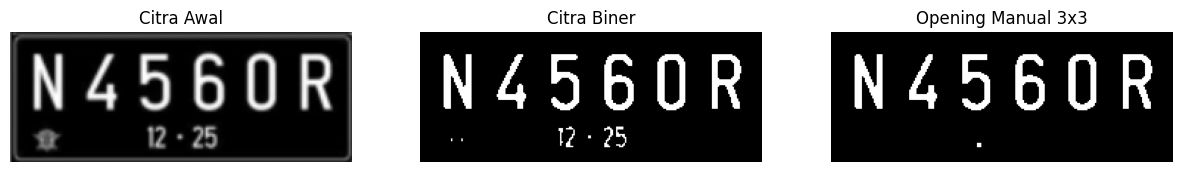

In [21]:
img, biner = baca_biner('plat_nomer.png')

SE = np.ones((3, 3), dtype=np.uint8)

hasil_opening_manual = dilasi_manual(
    erosi_manual(biner, SE), SE
)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(biner, cmap='gray')
plt.title('Citra Biner')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(hasil_opening_manual, cmap='gray')
plt.title('Opening Manual 3x3')
plt.axis('off')

plt.show()

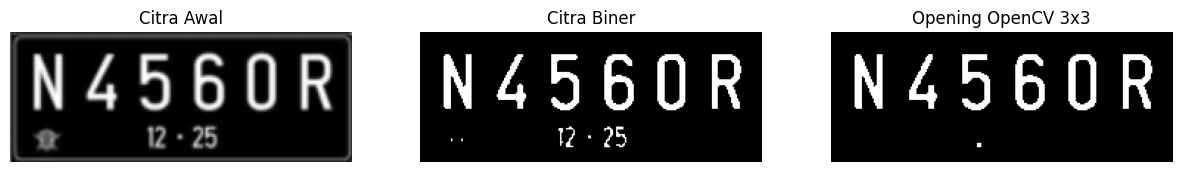

In [22]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
hasil_opening_cv = cv2.morphologyEx(
    biner, cv2.MORPH_OPEN, kernel
)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(biner, cmap='gray')
plt.title('Citra Biner')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(hasil_opening_cv, cmap='gray')
plt.title('Opening OpenCV 3x3')
plt.axis('off')

plt.show()

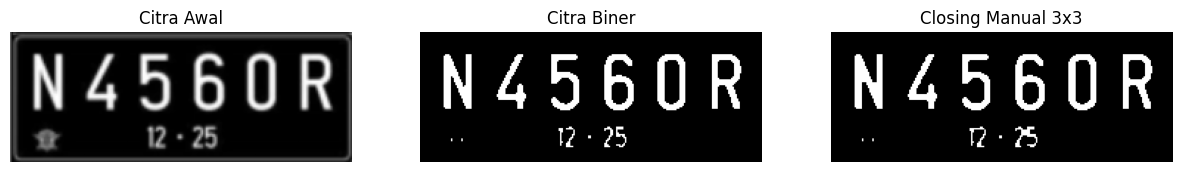

In [23]:
img, biner = baca_biner('plat_nomer.png')

SE = np.ones((3, 3), dtype=np.uint8)

hasil_closing_manual = erosi_manual(
    dilasi_manual(biner, SE), SE
)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(biner, cmap='gray')
plt.title('Citra Biner')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(hasil_closing_manual, cmap='gray')
plt.title('Closing Manual 3x3')
plt.axis('off')

plt.show()

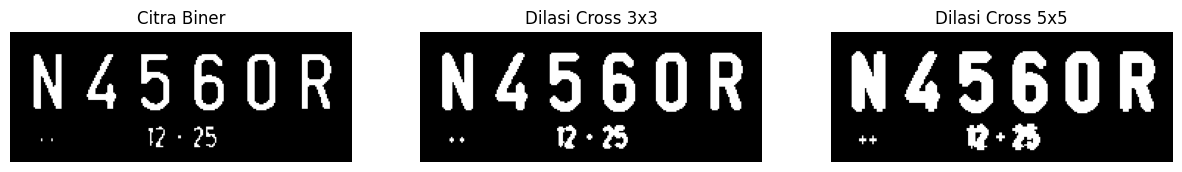

Structuring Element Cross 3x3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]

Structuring Element Cross 5x5:
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]


In [24]:
img, biner = baca_biner('plat_nomer.png')

SE_cross3 = cv2.getStructuringElement(
    cv2.MORPH_CROSS, (3, 3)
)

SE_cross5 = cv2.getStructuringElement(
    cv2.MORPH_CROSS, (5, 5)
)

hasil_cross3 = dilasi_manual(biner, SE_cross3)
hasil_cross5 = dilasi_manual(biner, SE_cross5)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(biner, cmap='gray')
plt.title('Citra Biner')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(hasil_cross3, cmap='gray')
plt.title('Dilasi Cross 3x3')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(hasil_cross5, cmap='gray')
plt.title('Dilasi Cross 5x5')
plt.axis('off')

plt.show()

print('Structuring Element Cross 3x3:')
print(SE_cross3)

print('\nStructuring Element Cross 5x5:')
print(SE_cross5)

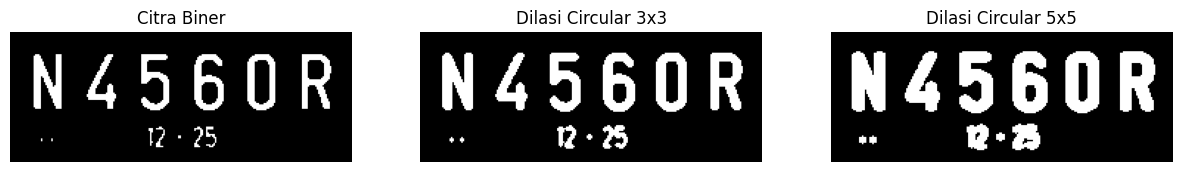

SE Circular 3x3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]

SE Circular 5x5:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


In [25]:
img, biner = baca_biner('plat_nomer.png')

SE_circle3 = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

SE_circle5 = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (5, 5)
)

hasil_circle3 = dilasi_manual(biner, SE_circle3)
hasil_circle5 = dilasi_manual(biner, SE_circle5)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(biner, cmap='gray')
plt.title('Citra Biner')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(hasil_circle3, cmap='gray')
plt.title('Dilasi Circular 3x3')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(hasil_circle5, cmap='gray')
plt.title('Dilasi Circular 5x5')
plt.axis('off')

plt.show()

print('SE Circular 3x3:')
print(SE_circle3)

print('\nSE Circular 5x5:')
print(SE_circle5)

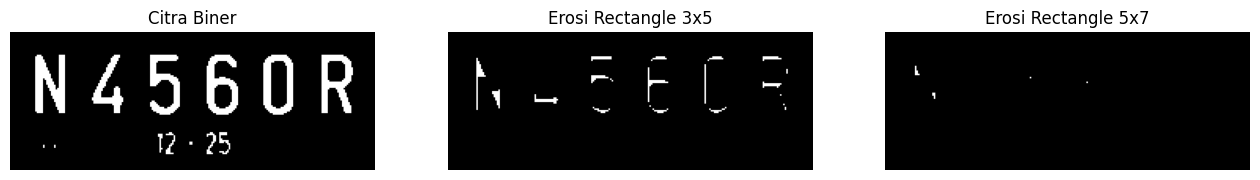

In [26]:
img, biner = baca_biner('plat_nomer.png')

SE_rect_3x5 = cv2.getStructuringElement(
    cv2.MORPH_RECT, (5, 3)
)

SE_rect_5x7 = cv2.getStructuringElement(
    cv2.MORPH_RECT, (7, 5)
)

hasil_rect_3x5 = erosi_manual(biner, SE_rect_3x5)
hasil_rect_5x7 = erosi_manual(biner, SE_rect_5x7)

plt.figure(figsize=(16, 4))

plt.subplot(1, 3, 1)
plt.imshow(biner, cmap='gray')
plt.title('Citra Biner')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(hasil_rect_3x5, cmap='gray')
plt.title('Erosi Rectangle 3x5')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(hasil_rect_5x7, cmap='gray')
plt.title('Erosi Rectangle 5x7')
plt.axis('off')

plt.show()

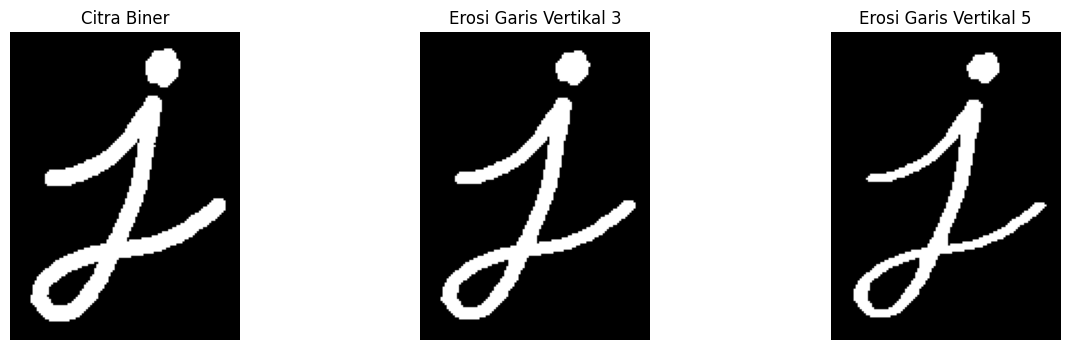

In [27]:
import os

nama_file = 'j.png'
path = f'{image_dir}/{nama_file}'

if not os.path.exists(path):
    raise FileNotFoundError(
        f'{nama_file} belum ditemukan di {image_dir}. '
        'Upload gambar j.png ke folder tersebut terlebih dahulu.'
    )

img, biner = baca_biner(nama_file)

SE_vertical3 = cv2.getStructuringElement(
    cv2.MORPH_RECT, (1, 3)
)

SE_vertical5 = cv2.getStructuringElement(
    cv2.MORPH_RECT, (1, 5)
)

hasil_vertical3 = erosi_manual(biner, SE_vertical3)
hasil_vertical5 = erosi_manual(biner, SE_vertical5)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(biner, cmap='gray')
plt.title('Citra Biner')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(hasil_vertical3, cmap='gray')
plt.title('Erosi Garis Vertikal 3')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(hasil_vertical5, cmap='gray')
plt.title('Erosi Garis Vertikal 5')
plt.axis('off')

plt.show()

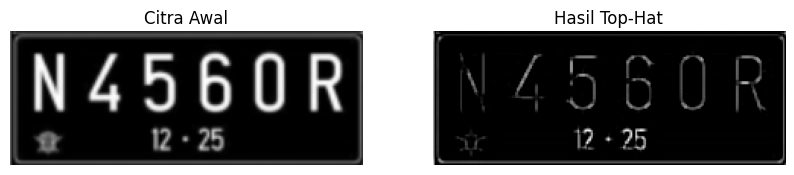

In [28]:
img, biner = baca_biner('plat_nomer.png')

kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (3, 3)
)

hasil_tophat = cv2.morphologyEx(
    img, cv2.MORPH_TOPHAT, kernel
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(hasil_tophat, cmap='gray')
plt.title('Hasil Top-Hat')
plt.axis('off')

plt.show()

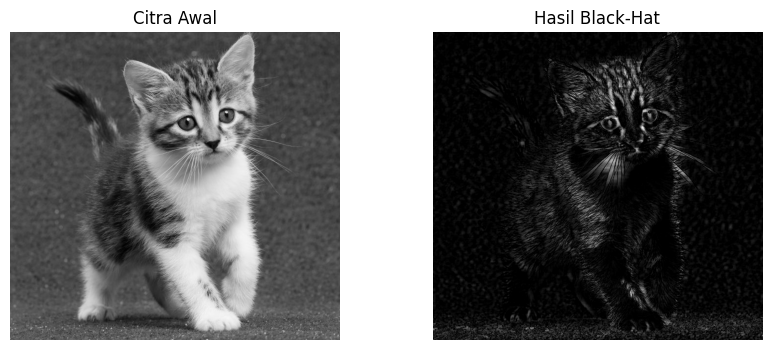

In [30]:
img, _ = baca_biner('kitten01.jpg', threshold=127)

kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (13, 5)
)

hasil_blackhat = cv2.morphologyEx(
    img, cv2.MORPH_BLACKHAT, kernel
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(hasil_blackhat, cmap='gray')
plt.title('Hasil Black-Hat')
plt.axis('off')

plt.show()

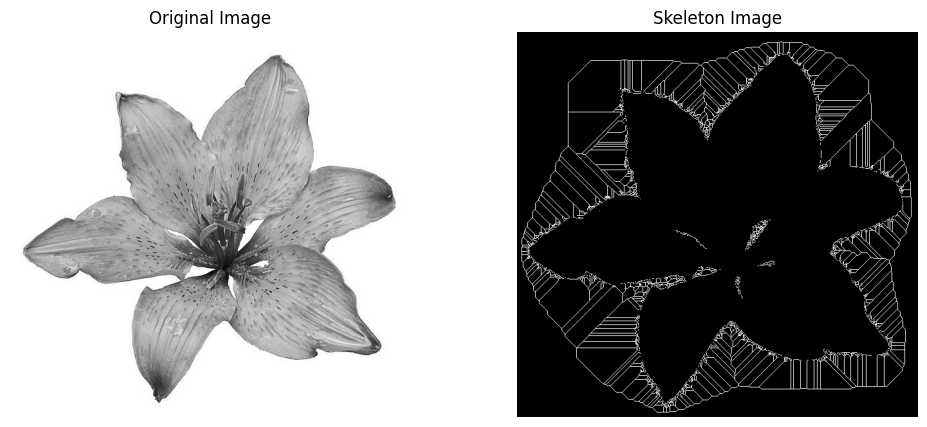

In [31]:
img = cv2.imread(
    f'{image_dir}/lily.jpg',
    cv2.IMREAD_GRAYSCALE
)

if img is None:
    raise FileNotFoundError('Gambar lily.jpg tidak ditemukan.')

threshold = filters.threshold_triangle(img)
binary = img > threshold

skeleton = skeletonize(binary)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(skeleton, cmap='gray')
plt.title('Skeleton Image')
plt.axis('off')

plt.show()

plt.imsave(
    'binary_and_bin_skeleton.png',
    skeleton,
    cmap='gray'
)

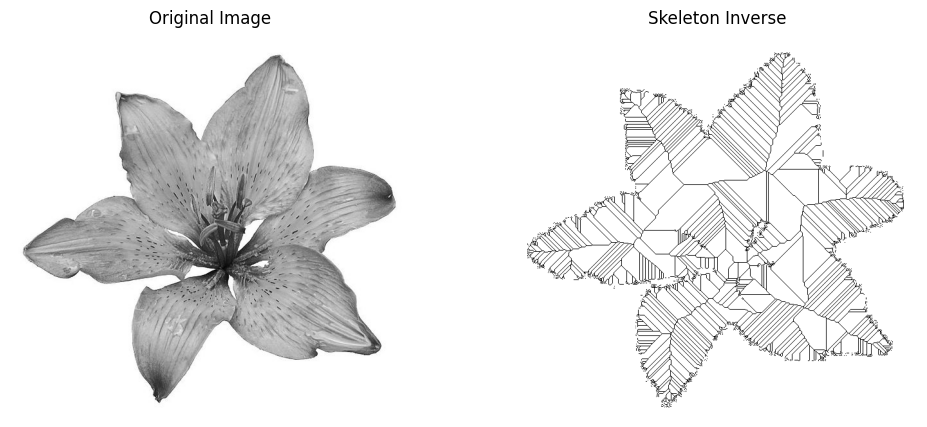

In [32]:
img = cv2.imread(
    f'{image_dir}/lily.jpg',
    cv2.IMREAD_GRAYSCALE
)

if img is None:
    raise FileNotFoundError('Gambar lily.jpg tidak ditemukan.')

threshold = filters.threshold_triangle(img)
binary_inverse = img < threshold

skeleton_inverse = skeletonize(binary_inverse)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(img, cmap='gray')
ax[0].set_title('Original Image')
ax[0].axis('off')

ax[1].imshow(skeleton_inverse, cmap='gray_r')
ax[1].set_title('Skeleton Inverse')
ax[1].axis('off')

plt.show()

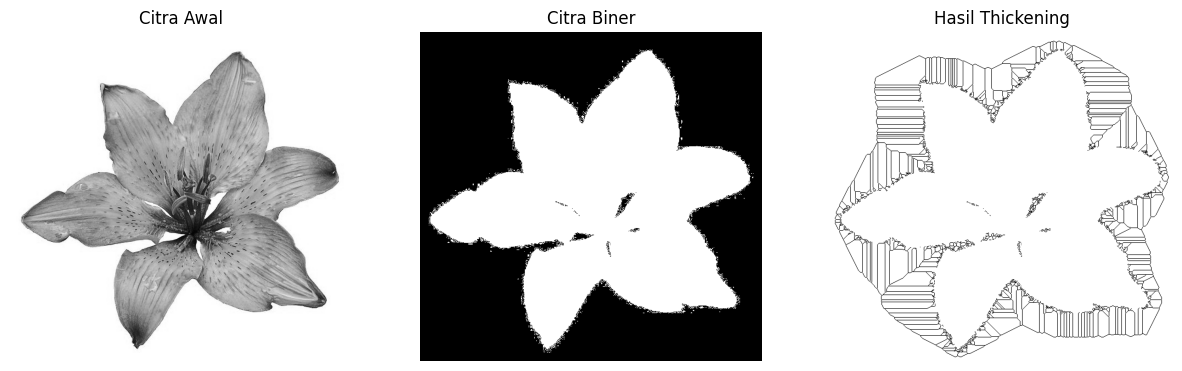

In [33]:
img = io.imread(f'{image_dir}/lily.jpg')

# Ubah citra RGB menjadi grayscale jika diperlukan
if img.ndim == 3:
    gray = color.rgb2gray(img)
else:
    gray = img.astype(np.float64)

# Normalisasi jika citra masih menggunakan rentang 0–255
if gray.max() > 1:
    gray = gray / 255.0

# Threshold untuk membentuk citra biner
threshold = filters.threshold_triangle(gray)
binary = gray < threshold

# Thickening menggunakan pendekatan dual dari thinning
background = ~binary
background_thin = thin(background)
thickened = ~background_thin

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(binary, cmap='gray')
plt.title('Citra Biner')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(thickened, cmap='gray')
plt.title('Hasil Thickening')
plt.axis('off')

plt.show()

# Tugas Praktikum


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


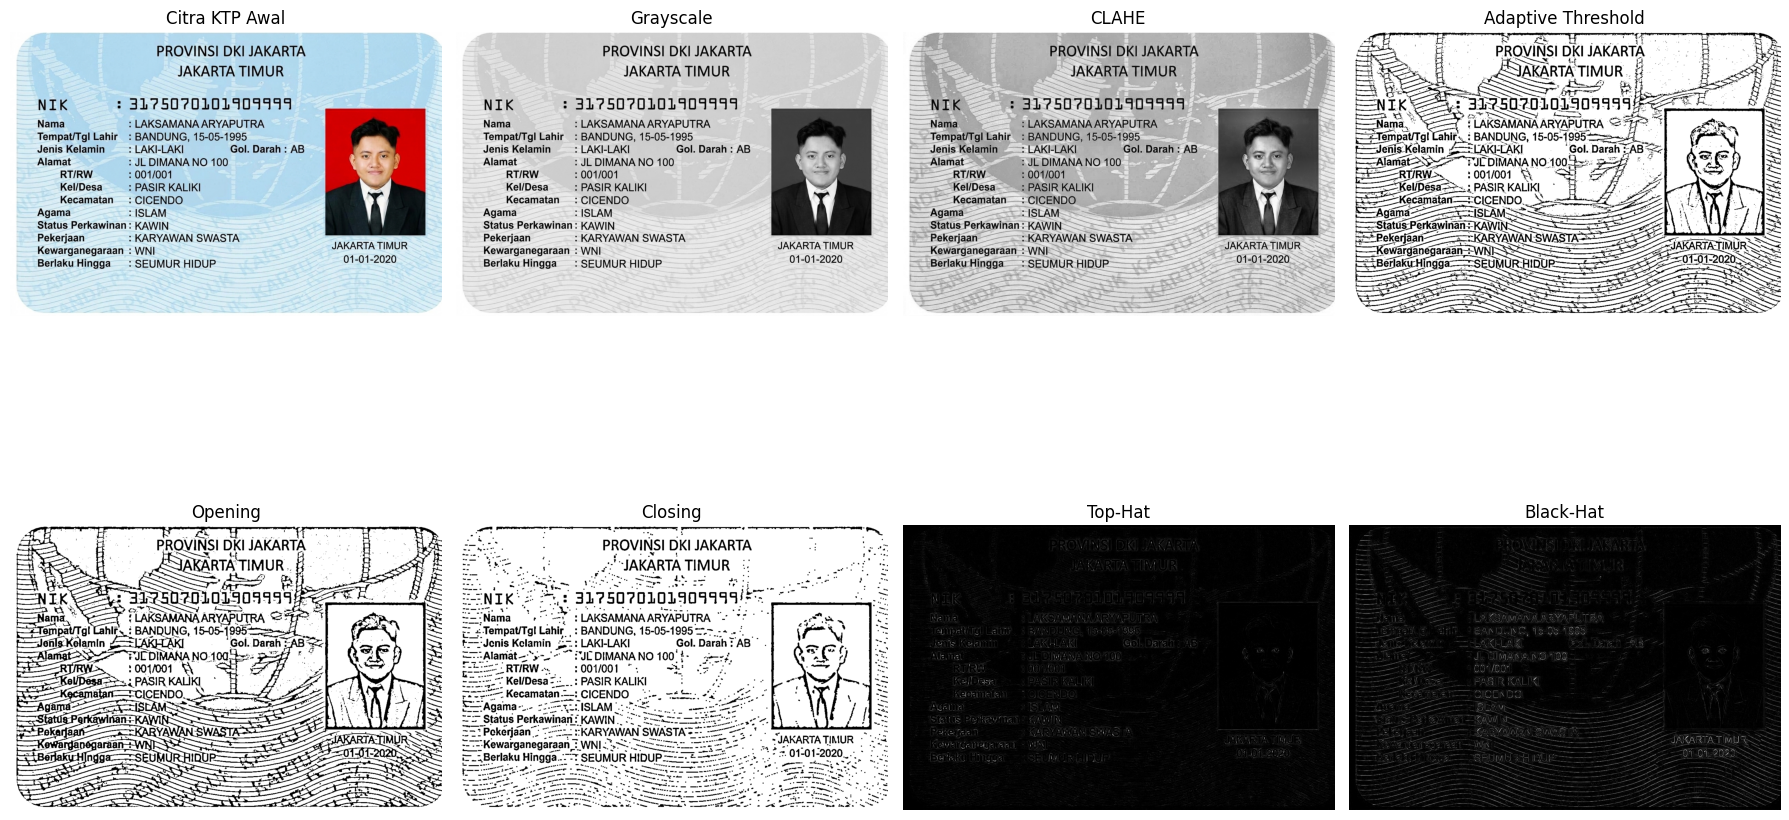

In [35]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

# Baca gambar KTP
path = '/content/drive/MyDrive/PCVK_img/ktp_laksa_dummy.jpg'
img = cv2.imread(path)

if img is None:
    raise FileNotFoundError(f'Gambar tidak ditemukan: {path}')

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Tingkatkan kontras lokal
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)
enhanced = clahe.apply(gray)

# Threshold adaptif untuk teks dan latar
binary = cv2.adaptiveThreshold(
    enhanced,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    10
)

# Structuring element
kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (3, 3)
)

# Operasi morfologi
opening = cv2.morphologyEx(
    binary, cv2.MORPH_OPEN, kernel
)

closing = cv2.morphologyEx(
    binary, cv2.MORPH_CLOSE, kernel
)

tophat = cv2.morphologyEx(
    enhanced, cv2.MORPH_TOPHAT, kernel
)

blackhat = cv2.morphologyEx(
    enhanced, cv2.MORPH_BLACKHAT, kernel
)

# Visualisasi hasil
images = [
    (img[:, :, ::-1], 'Citra KTP Awal'),
    (gray, 'Grayscale'),
    (enhanced, 'CLAHE'),
    (binary, 'Adaptive Threshold'),
    (opening, 'Opening'),
    (closing, 'Closing'),
    (tophat, 'Top-Hat'),
    (blackhat, 'Black-Hat')
]

plt.figure(figsize=(18, 12))

for i, (image, title) in enumerate(images, 1):
    plt.subplot(2, 4, i)
    plt.imshow(
        image,
        cmap=None if image.ndim == 3 else 'gray'
    )
    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()
